## Algorithm: Solving the Korteweg–de Vries Equation with FFT

### The PDE

$$\frac{\partial u}{\partial t} + 6u \frac{\partial u}{\partial x} + \frac{\partial^3 u}{\partial x^3} = 0$$

Rearranged for time integration:

$$\frac{\partial u}{\partial t} = -6u \frac{\partial u}{\partial x} - \frac{\partial^3 u}{\partial x^3}$$

Two competing effects:

- **Nonlinear advection** ($-6u\, u_x$): taller parts of the wave travel faster, tending to steepen it (same mechanism as Burgers').
- **Dispersion** ($-u_{xxx}$): different frequency components travel at different speeds, spreading the wave out.

When these two effects are perfectly balanced, the result is a **soliton** — a stable, shape-preserving travelling wave that passes through other solitons without changing form.

### Exact Soliton Solution

A single soliton with speed $c > 0$ travelling to the right:

$$u(x, t) = \frac{c}{2} \operatorname{sech}^2\!\left(\frac{\sqrt{c}}{2}(x - ct)\right)$$

Faster solitons are **taller and narrower**; slower solitons are **shorter and wider**.

### Initial Condition

Two solitons with speeds $c_1 = 4$ and $c_2 = 1$. The faster, taller soliton starts to the left and overtakes the slower, shorter one. After the interaction both re-emerge unchanged in shape and speed — the defining property of solitons, first observed numerically by Zabusky and Kruskal (1965).

### How `rhsKdV` works

At each time step, given the current $u(x)$:

1. **FFT** $u$ $\to$ $\hat{u}$
2. **First derivative**: $\widehat{u_x} = i\kappa\, \hat{u}$ $\to$ iFFT $\to$ $u_x$
3. **Third derivative**: $\widehat{u_{xxx}} = (i\kappa)^3\, \hat{u} = -i\kappa^3\, \hat{u}$ $\to$ iFFT $\to$ $u_{xxx}$
4. **Combine** (rearranged form): $du/dt = -6u \cdot u_x - u_{xxx}$

The nonlinear term $-6u \cdot u_x$ couples all Fourier modes (as in Burgers'), so it must be evaluated in physical space. The dispersive term $-u_{xxx}$ is **linear with constant coefficients**, so it is computed entirely in Fourier space.

### Comparison with Burgers' Equation

| | Burgers | KdV |
|---|---|---|
| PDE | $u_t + u\, u_x - \nu\, u_{xx} = 0$ | $u_t + 6u\, u_x + u_{xxx} = 0$ |
| Highest-order term | 2nd order (diffusive) | 3rd order (dispersive) |
| Effect of nonlinearity | Shock formation | Soliton formation |
| Effect of linear term | Smoothing (dissipative) | Spreading (conservative) |
| Long-time behaviour | Diffusing shock | Colliding, shape-preserving solitons |

/tmp/ipykernel_400611/1005884479.py:34: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  u = odeint(rhsKdV, u0, t, args=(kappa,), rtol=1e-8, atol=1e-10)


ValueError: Axis limits cannot be NaN or Inf

/app/sreeram/datascience/.venv/lib/python3.12/site-packages/mpl_toolkits/mplot3d/proj3d.py:148: RuntimeWarning: invalid value encountered in dot
  vecw = np.dot(M, vec.data)


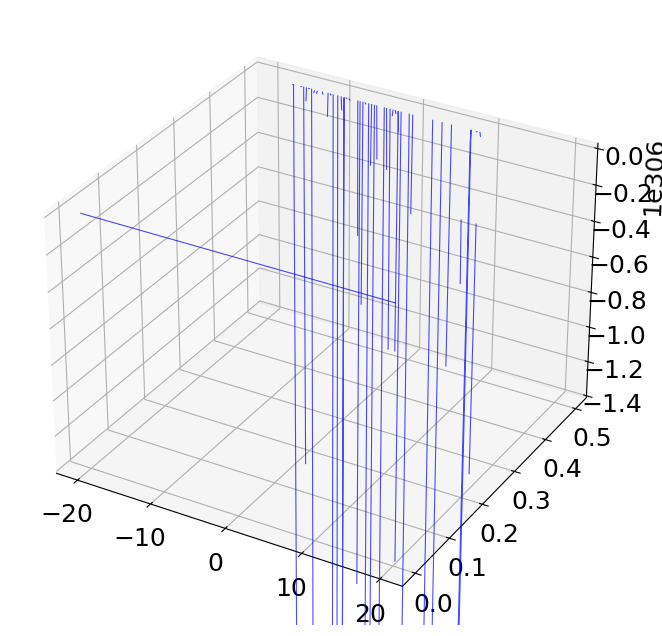

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from mpl_toolkits.mplot3d import axes3d

plt.rcParams['figure.figsize'] = [12, 12]
plt.rcParams.update({'font.size': 18})

L = 40      # Length of domain
N = 512     # Number of discretization points
dx = L / N
x = np.arange(-L/2, L/2, dx)

# Discrete wavenumbers
kappa = 2 * np.pi * np.fft.fftfreq(N, d=dx)

# Initial condition: two solitons — faster (c1=4) starts to the left
c1, c2 = 4.0, 1.0
u0 = (c1/2) / np.cosh((np.sqrt(c1)/2) * (x + 8))**2 + \
     (c2/2) / np.cosh((np.sqrt(c2)/2) * (x - 2))**2

# Time: solitons meet around t ~ 3.3, run to t = 5 to see them separate
dt = 0.025
t = np.arange(0, 200*dt, dt)

def rhsKdV(u, t, kappa):
    uhat     = np.fft.fft(u)
    du_hat   =  1j * kappa      * uhat   # first derivative: i*kappa
    dddu_hat = -1j * kappa**3   * uhat   # third derivative: (i*kappa)^3 = -i*kappa^3
    du   = np.fft.ifft(du_hat).real
    dddu = np.fft.ifft(dddu_hat).real
    return -6 * u * du - dddu

u = odeint(rhsKdV, u0, t, args=(kappa,), rtol=1e-8, atol=1e-10)

# --- Waterfall plot ---
fig = plt.figure(figsize=(14, 8))
ax = fig.add_subplot(111, projection='3d')

step = 10
u_plot = u[::step, :]
t_plot = t[::step]

for j in range(u_plot.shape[0]):
    ax.plot(x, t_plot[j] * np.ones(len(x)), u_plot[j, :], 'b', lw=0.8, alpha=0.7)

ax.set_title('KdV — Two-Soliton Interaction')
ax.set_xlabel('x')
ax.set_ylabel('time')
ax.set_zlabel('u')
ax.set_xlim([-20, 20])
ax.set_ylim([t_plot[0], t_plot[-1]])
ax.view_init(elev=25, azim=-50)   # angle that shows both x-movement and time depth
plt.tight_layout()
plt.show()

# --- Heatmap: time vs position ---
fig, ax2 = plt.subplots(figsize=(12, 6))
im = ax2.imshow(
    u,
    aspect='auto',
    extent=[x[0], x[-1], t[-1], t[0]],   # x on horizontal, time on vertical
    cmap='viridis',
    origin='upper'
)
plt.colorbar(im, ax=ax2, label='u')
ax2.set_xlabel('x')
ax2.set_ylabel('time')
ax2.set_title('KdV — Two-Soliton Heatmap (brighter = larger amplitude)')
plt.tight_layout()
plt.show()

## Single-Soliton Verification

The exact single-soliton at time $T$ is just the initial profile shifted by $cT$:

$$u_{\text{exact}}(x, T) = \frac{c}{2} \operatorname{sech}^2\!\left(\frac{\sqrt{c}}{2}(x - x_0 - cT)\right)$$

We initialise with this exact profile and compare the numerical solution at $t = T$ against it. Close agreement confirms that the pseudospectral derivative and `odeint` are resolving the stiff third-derivative term accurately.

/tmp/ipykernel_400611/3280568297.py:9: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  u_single = odeint(rhsKdV, u0_single, t_single, args=(kappa,), rtol=1e-8, atol=1e-10)


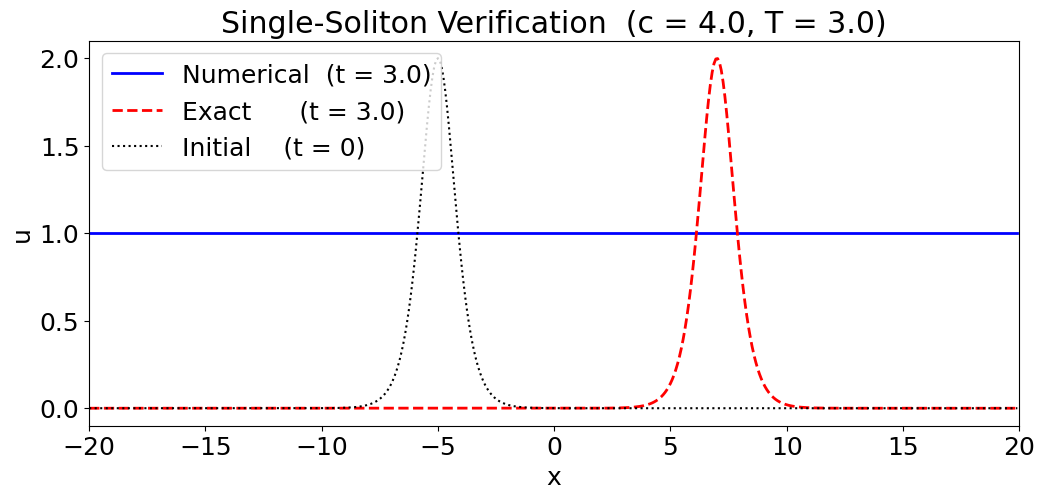

Max pointwise error: 1.00e+00


In [ ]:
# Single-soliton verification: numerical vs exact
c  = 4.0
T  = 3.0
x0 = -5.0   # initial soliton centre

u0_single = (c/2) / np.cosh((np.sqrt(c)/2) * (x - x0))**2

t_single = np.linspace(0, T, 200)
u_single = odeint(rhsKdV, u0_single, t_single, args=(kappa,), rtol=1e-8, atol=1e-10)

u_exact = (c/2) / np.cosh((np.sqrt(c)/2) * (x - x0 - c*T))**2

plt.figure(figsize=(12, 5))
plt.plot(x, u_single[-1, :], 'b',   lw=2,   label=f'Numerical  (t = {T})')
plt.plot(x, u_exact,         'r--', lw=2,   label=f'Exact      (t = {T})')
plt.plot(x, u0_single,       'k:',  lw=1.5, label='Initial    (t = 0)')
plt.xlim([-20, 20])
plt.legend()
plt.title(f'Single-Soliton Verification  (c = {c}, T = {T})')
plt.xlabel('x')
plt.ylabel('u')
plt.show()

print(f'Max pointwise error: {np.max(np.abs(u_single[-1, :] - u_exact)):.2e}')

## Why the Dispersive Term Can Stay in Fourier Space

The term $u_{xxx}$ is **linear with constant coefficients**. Taking the Fourier transform of $\partial^3 u / \partial x^3$:

$$\widehat{u_{xxx}}(k) = (ik)^3\,\hat{u}(k) = -ik^3\,\hat{u}(k)$$

Each mode $k$ is scaled by the constant $-ik^3$ independently — no mode couples to any other. This is identical to how Burgers' diffusion term $\nu\,u_{xx}$ is diagonal ($-\nu k^2 \hat{u}$). Both are **cheap**: $O(N)$ per time step.

### Contrast with the nonlinear term

The advection term $-6u\,u_x$ is a **product** of two spatial functions. Multiplication in physical space becomes **convolution** in Fourier space:

$$\widehat{6u\,u_x}(k) = 6\sum_{k'} \hat{u}(k')\cdot ik'\,\hat{u}(k - k')$$

Mode $k$ depends on every other mode $k'$ — an $O(N^2)$ convolution. The **pseudospectral** strategy avoids this:

1. Compute $u_x$ in Fourier space ($\hat{u}_x = i\kappa\,\hat{u}$), then iFFT to physical space.
2. Multiply $u \cdot u_x$ **pointwise** in physical space — $O(N)$.
3. Return only $u_{xxx}$ to Fourier space for the diagonal update.

### Summary

| Term | Fourier treatment | Cost |
|---|---|---|
| $\nu\, u_{xx}$ (Burgers diffusion) | diagonal: $-\nu k^2\,\hat{u}$ | $O(N)$ |
| $u_{xxx}$ (KdV dispersion) | diagonal: $-ik^3\,\hat{u}$ | $O(N)$ |
| $u\, u_x$ (nonlinear advection) | convolution → use physical space | $O(N \log N)$ via FFT |

The KdV equation is **energy-conserving** ($\|u\|_{L^2}$ is constant), unlike Burgers' with $\nu > 0$. This is why solitons re-emerge intact after collision instead of decaying.